# Single Experiment Fine-tuning Analysis

This notebook reproduces the baseline workflow from notebook 01, then fine-tunes a separate copy of the pretrained normalizing flow with one training pass over simulations drawn from the experiment prior. It compares baseline and fine-tuned MAP estimates and constraint-MAPE for three experiments.

Run from top to bottom. Fine-tuning is configured for 1,000 steps per experiment and uses CUDA.


## 1. Setup

Add the project root to `sys.path` so the pipeline modules are importable from within the `notebooks/` subdirectory.

In [1]:
%matplotlib inline

import sys
import os

# Add project root to path when running from notebooks/ subdirectory
PROJECT_ROOT = os.path.abspath(os.path.join(os.path.dirname("__file__"), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import torch
import numpy as np
import matplotlib.pyplot as plt
from device_utils import summarize_torch_backends

backend_summary = summarize_torch_backends()
if not torch.cuda.is_available():
    raise RuntimeError("CUDA was requested, but torch.cuda.is_available() is False.")
device = f"cuda:{torch.cuda.current_device()}"
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA (NVIDIA GPU) available  : {backend_summary['cuda']}")
print(f"MPS (Apple Silicon) available   : {backend_summary['mps']}")
print(f"Device          : {device}")
print(f"Project root    : {PROJECT_ROOT}")


PyTorch version : 2.7.1+cu118
CUDA (NVIDIA GPU) available  : True
MPS (Apple Silicon) available   : False
Device          : cuda:0
Project root    : /home/levytskyi/Documents/inverse-eval


## 2. Choose an Experiment

Set `EXPERIMENT_ID` to a sample identifier in `sXXXXXX` format (e.g. `"s000004"`).
Available IDs can be found by listing `dataset/test/`.
`LAYER_COUNT` describes the film layer structure used for prior construction and parameter parsing.

In [2]:
# fixed parameters for this notebook
LAYER_COUNT   = 1           # picking an experiment with different layer counts will require different model (NF_CONFIG)
NF_CONFIG     = "example_nf_config_reflectorch.yaml"

In [3]:
EXPERIMENT_ID = "s000004" # any experiment from 'dataset/test/'

In [4]:
# Parameters for the experiment
NF_SAMPLES    = 1000
PRIORS_DEV    = 30      # prior width as % of the model constraint range

# Preprocessing parameters
ENABLE_PREPROCESSING = True
ERROR_THRESHOLD      = 0.75
CONSECUTIVE          = 5

## 3. Discover Experiment Files

`parameter_discovery.discover_experiment_files` locates the reflectivity data file and the ground-truth model file for the chosen experiment.

In [5]:
from pathlib import Path
from config import DATA_DIRECTORY
from parameter_discovery import parse_true_parameters_from_model_file

data_dir   = Path(PROJECT_ROOT) / DATA_DIRECTORY
data_file  = data_dir / f"{EXPERIMENT_ID}_experimental_curve.dat"
model_file = data_dir / f"{EXPERIMENT_ID}_model.txt"

print(f"Data file (measured curve) : {data_file}")
print(f"Model file (ground truth parameters): {model_file}")

# Parse true structural parameters from the model file
true_params_dict = parse_true_parameters_from_model_file(model_file)

layer_key   = f"{LAYER_COUNT}_layer"
param_names = true_params_dict[layer_key]["param_names"]
true_params  = true_params_dict[layer_key]["params"]

print(f"\nTrue parameters ({LAYER_COUNT}-layer):")
for name, val in zip(param_names, true_params):
    print(f"  {name:<20} = {val:.4f}")


Data file (measured curve) : /home/levytskyi/Documents/inverse-eval/dataset/test/s000004_experimental_curve.dat
Model file (ground truth parameters): /home/levytskyi/Documents/inverse-eval/dataset/test/s000004_model.txt

True parameters (1-layer):
  thickness            = 28.6300
  amb_rough            = 8.0400
  sub_rough            = 7.0400
  layer_sld            = 3.5671
  sub_sld              = 9.7987


## 4. Load and Preprocess Experimental Data

The preprocessing step truncates the Q-range at the first run of consecutive high relative-error points.
This prevents tensor concatenation errors during NF inference.

In [6]:
from simple_pipeline import load_experimental_data


q_exp, curve_exp, sigmas_exp = load_experimental_data(
    data_file_path=data_file,
    enable_preprocessing=ENABLE_PREPROCESSING,
    threshold=ERROR_THRESHOLD,
    consecutive=CONSECUTIVE,
)


## 5. Build Constraint-Based Prior Bounds

The prior bounds are constructed with width `PRIORS_DEV`% of each model constraint range, centred on the true parameter.
The window is additionally clipped to the physical constraint ranges defined in `model_constraints.json`.

In [7]:
from parameter_discovery import get_prior_bounds_for_experiment

prior_bounds = get_prior_bounds_for_experiment(
    experiment_id=EXPERIMENT_ID,
    true_params_dict=true_params_dict,
    layer_count=LAYER_COUNT,
    priors_type="constraint_based",
    deviation=PRIORS_DEV / 100.0,
)

print("Prior bounds (constraint-based, deviation = {:.0%}):".format(PRIORS_DEV / 100.0))
print(f"{'Parameter':<20}  {'Min':>10}  {'True':>10}  {'Max':>10}")
print("-" * 56)
for name, val, (lo, hi) in zip(param_names, true_params, prior_bounds):
    print(f"{name:<20}  {lo:>10.4f}  {val:>10.4f}  {hi:>10.4f}")


Prior bounds (constraint-based, deviation = 30%):
Parameter                    Min        True         Max
--------------------------------------------------------
thickness                 1.0000     28.6300    300.7000
amb_rough                 0.0000      8.0400     18.0000
sub_rough                 0.0000      7.0400     18.0000
layer_sld                 1.0671      3.5671      6.0671
sub_sld                   7.2987      9.7987     12.2987


## 6. Load Model and Run Inference

`EasyInferenceModel` loads the trained NF weights and config. `preprocess_and_sample` interpolates the data onto the model Q-grid and draws `NF_SAMPLES` posterior samples via importance-weighted sampling.

In [8]:
from reflectorch import EasyInferenceModel
from simple_pipeline import _extend_prior_bounds_for_nf

torch.manual_seed(420)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA was requested, but torch.cuda.is_available() is False.")
device = f"cuda:{torch.cuda.current_device()}"
inference_model = EasyInferenceModel(
    config_name=NF_CONFIG,
    device=device,
)
print(f"Using inference device: {device}")

# Interpolate onto the model Q-grid (includes sigmas for dR-aware models)
q_model, curve_interp, sigmas_interp = inference_model.interpolate_data_to_model_q(
    q_exp, curve_exp, sigmas_exp=sigmas_exp
)

# Extend prior bounds with nuisance parameters (r_scale, log10_background)
# required by the NF model, handled automatically by _extend_prior_bounds_for_nf
prior_bounds_nf = _extend_prior_bounds_for_nf(prior_bounds)

prediction_dict = inference_model.preprocess_and_sample(
    reflectivity_curve=curve_interp,
    q_values=q_model,
    sigmas=sigmas_interp,
    ambient_sld=float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6),
    num_samples=NF_SAMPLES,
    prior_bounds=prior_bounds_nf,
    q_resolution=0.1,
    clip_prediction=True,
    enable_error_bars_filtering=False,  # q_exp was already preprocessed above
    calc_sampled_curves=True,
    calc_sampled_sld_profiles=True,
    calc_log_likelihoods=True,
    enable_importance_sampling=True,
)

print("Inference complete.")
print(f"Sampled params shape : {prediction_dict['predicted_params_array'].shape}")
print(f"Parameter names      : {prediction_dict['param_names']}")


Configuration file `/home/levytskyi/Documents/inverse-eval/vendor/nflows_reflectorch/configs/example_nf_config_reflectorch.yaml` found locally.
Weights file `/home/levytskyi/Documents/inverse-eval/vendor/nflows_reflectorch/saved_models/model_example_nf_config_reflectorch.safetensors` found locally.
Model example_nf_config_reflectorch.yaml loaded. Number of parameters: 40.91 M
The model corresponds to a `standard_model` parameterization with 1 layers (7 predicted parameters)
Parameter types and total ranges:
- thicknesses: [1.0, 1500.0]
- roughnesses: [0.0, 60.0]
- slds: [-8.0, 16.0]
- r_scale: [0.9, 1.1]
- log10_background: [-10.0, -4.0]
Allowed widths of the prior bound intervals (max-min):
- thicknesses: [0.01, 1500.0]
- roughnesses: [0.01, 60.0]
- slds: [0.01, 24.0]
- r_scale: [0.001, 0.2]
- log10_background: [0.01, 6.0]
The model was trained on curves discretized at exactly 256 uniform points, between q_min in [0.001, 0.02] and q_max in [0.05, 0.4]
The model was trained with linear

/tmp/ipykernel_314978/1178496458.py:27: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=1`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  ambient_sld=float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6),
/home/levytskyi/Documents/inverse-eval/.venv/lib/python3.12/site-packages/nflows/transforms/coupling.py:481: UserWarning: Inputs to the softmax are not scaled down: initialization might be bad.
  warnings.warn(



################################################################################
### STARTING INFERENCE SAMPLE() METHOD ###
################################################################################

[sample] Prior bounds shape: (7, 2)
[sample] Scaled prior bounds dtype: torch.float32, shape: torch.Size([1, 14])

[sample] ========== PREPROCESSING INPUTS ==========

[sample] Input reflectivity_curve type: <class 'numpy.ndarray'>
  - numpy dtype: float64, shape: (256,)
  - range: [1.302325e-06, 1.008075e+00]
[sample] Input q_values type: <class 'numpy.ndarray'>
  - numpy dtype: float64, shape: (256,)
  - range: [7.007200e-03, 1.736530e-01]
[sample] q_values converted to tensor:
  - dtype: torch.float32, shape: torch.Size([1, 256])
  - range: [7.007200e-03, 1.736530e-01]

[sample] Calling _scale_curve()...
[sample] scaled_curve output:
  - dtype: torch.float32, shape: torch.Size([1, 256])
  - range: [-1.770495e-01, 1.000699e+00]

[sample] Computing scaled_q_values (train_with_q_inp

## 7. Extract MAP Estimate

Select the highest log-likelihood sample as the MAP (maximum a posteriori) estimate.

In [9]:
from nf_statistics import compute_nf_sample_statistics

log_likelihoods = prediction_dict["log_likelihoods"]
pred_params     = prediction_dict["predicted_params_array"]
nf_param_names  = prediction_dict["param_names"]

best_idx   = int(np.argmax(log_likelihoods))
map_params = pred_params[best_idx]

print(f"MAP sample index     : {best_idx}")
print(f"MAP log-likelihood   : {log_likelihoods[best_idx]:.4f}")
print()

stats = compute_nf_sample_statistics(pred_params, log_likelihoods)

print(f"{'Parameter':<20}  {'True':>10}  {'MAP':>10}  {'Mean':>10}  {'Std':>10}")
print("-" * 66)
for i, name in enumerate(nf_param_names):
    true_val = true_params[i] if i < len(true_params) else float("nan")
    print(
        f"{name:<20}  {true_val:>10.4f}  {map_params[i]:>10.4f}"
        f"  {stats['nf_params_mean'][i]:>10.4f}  {stats['nf_params_std'][i]:>10.4f}"
    )


MAP sample index     : 981
MAP log-likelihood   : -91.8939

Parameter                   True         MAP        Mean         Std
------------------------------------------------------------------
Thickness L1             28.6300     80.9536     99.6075     21.1605
Roughness L1              8.0400      0.0000      1.6485      2.7609
Roughness sub             7.0400      7.3711      7.6125      2.3474
SLD L1                    3.5671      3.4650      3.5720      1.3371
SLD sub                   9.7987      9.8226      9.7707      0.2959
r_scale                      nan      0.9733      0.9730      0.0014
log10_background             nan    -10.0000     -7.7127      1.4677


## 8. Visualise Reflectivity Curve Fit and SLD Profile

`plot_simple_comparison` produces a two-panel figure: the experimental curve with the MAP fit overlaid, and the corresponding SLD depth profile.

/tmp/ipykernel_314978/3412995683.py:8: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=1`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  fronting_sld = float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6)
/home/levytskyi/Documents/inverse-eval/plotting_utils.py:229: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/home/levytskyi/Documents/inverse-eval/plotting_utils.py:232: UserWarning: FigureCanvasPdf is non-interactive, and thus cannot be shown
  plt.show()


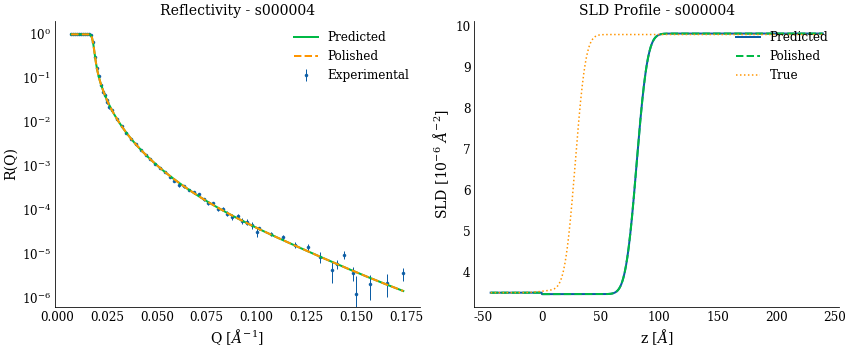

In [10]:
from plotting_utils import plot_simple_comparison
from parameter_discovery import generate_true_sld_profile

# Disable LaTeX rendering for better compatibility
plt.rcParams["text.usetex"] = False

predicted_sld_x = np.asarray(prediction_dict["sampled_sld_xaxis"])
fronting_sld = float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6)
true_sld_x, true_sld_y = generate_true_sld_profile(
    true_params_dict, ambient_sld=fronting_sld, x_axis=predicted_sld_x
)

plot_simple_comparison(
    q_exp=q_exp,
    curve_exp=curve_exp,
    sigmas_exp=sigmas_exp,
    q_model=np.asarray(prediction_dict["q_plot_pred"]),
    predicted_curve=np.asarray(prediction_dict["sampled_curves"])[best_idx],
    polished_curve=np.asarray(prediction_dict["sampled_curves"])[best_idx],
    predicted_sld_x=predicted_sld_x,
    predicted_sld_y=np.asarray(prediction_dict["sampled_sld_profiles"])[best_idx],
    polished_sld_y=np.asarray(prediction_dict["sampled_sld_profiles"])[best_idx],
    true_sld_x=true_sld_x,
    true_sld_y=true_sld_y,
    experiment_name=EXPERIMENT_ID,
)


## 9. Compute Constraint MAPE Metrics

Constraint MAPE normalises the absolute prediction error by the prior half-width rather than the true value:

$$\text{Constraint MAPE} = \frac{|\hat{y} - y|}{\text{constraint width}} \times 100$$

A value of 0 means the prediction equals the true value; 100 means the prediction is at the constraint boundary.

In [11]:
from error_calculation import calculate_parameter_metrics, print_metrics_report

# Slice to structural params only (exclude nuisance: r_scale, log10_background).
# Use `param_names` (standardized keys from parameter_discovery) rather than
# `nf_param_names` (human-readable NF labels) so get_constraint_width can look
# them up in model_constraints.json.
n_structural = len(true_params)
map_params_structural = map_params[:n_structural]

param_metrics = calculate_parameter_metrics(
    pred_params=map_params_structural,
    true_params=true_params,
    param_names=param_names,
    prior_bounds=prior_bounds,
    priors_type="constraint_based",
)

print_metrics_report(param_metrics=param_metrics)



METRICS REPORT: Model

PARAMETER ACCURACY:
  Overall Constraint-based MAPE: 3.94%
  (Traditional MAPE:             58.11%)
  Overall MSE:            560.504215

  By Parameter Type:
    Thickness:
      Constraint-based MAPE: 5.24%
      (Traditional MAPE:     182.76%)
      MSE:  2737.758819
    Roughness:
      Constraint-based MAPE: 6.98%
      (Traditional MAPE:     52.35%)
      MSE:  32.375627
    Sld:
      Constraint-based MAPE: 0.26%
      (Traditional MAPE:     1.55%)
      MSE:  0.005502

QUALITY ASSESSMENT:
  Parameter Accuracy: EXCELLENT (Constraint-based MAPE < 5%)



## 10. Fine-tune and compare the selected experiment

The pretrained trainer remains unchanged; `fine_tune_nflow` trains a separate copy. Each training step simulates a batch from the experiment prior and continues maximum-likelihood training on the copied model. The measurement is interpolated to the model Q-grid using the same preprocessing and resolution as baseline inference.

Configuration: 1,000 training steps in one pass, batch size 2,048, AdamW, learning rate `1e-5`, and 1,000 inference samples. Training is performed on CUDA.


In [12]:
from reflectorch.runs import fine_tune_nflow

FINE_TUNE_MAX_STEPS = 1_000
FINE_TUNE_BATCH_SIZE = 2_048
FINE_TUNE_LEARNING_RATE = 1e-5
Q_RESOLUTION = 0.1
fronting_sld = float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6)

fine_tuned_trainer = fine_tune_nflow(
    trainer=inference_model.trainer,
    q_values=q_model,
    reflectivity_curve=curve_interp,
    uncertainty=sigmas_interp,
    prior_bounds=prior_bounds_nf,
    max_steps=FINE_TUNE_MAX_STEPS,
    batch_size=FINE_TUNE_BATCH_SIZE,
    learning_rate=FINE_TUNE_LEARNING_RATE,
    q_resolution=Q_RESOLUTION,
)

fine_tuned_inference = EasyInferenceModel(trainer=fine_tuned_trainer, device=device)
fine_tuned_prediction = fine_tuned_inference.preprocess_and_sample(
    reflectivity_curve=curve_interp,
    q_values=q_model,
    sigmas=sigmas_interp,
    num_samples=NF_SAMPLES,
    prior_bounds=prior_bounds_nf,
    q_resolution=Q_RESOLUTION,
    clip_prediction=True,
    enable_error_bars_filtering=False,
    calc_sampled_curves=True,
    calc_sampled_sld_profiles=True,
    calc_log_likelihoods=True,
    enable_importance_sampling=True,
)

fine_tuned_log_likelihoods = fine_tuned_prediction["log_likelihoods"]
fine_tuned_params = fine_tuned_prediction["predicted_params_array"]
fine_tuned_best_idx = int(np.argmax(fine_tuned_log_likelihoods))
fine_tuned_map_params = fine_tuned_params[fine_tuned_best_idx]
fine_tuned_metrics = calculate_parameter_metrics(
    pred_params=fine_tuned_map_params[:len(true_params)],
    true_params=true_params,
    param_names=param_names,
    prior_bounds=prior_bounds,
    priors_type="constraint_based",
)

print(f"Experiment: {EXPERIMENT_ID}")
print(f"Baseline constraint-MAPE : {param_metrics['overall']['constraint_mape']:.3f}%")
print(f"Fine-tuned constraint-MAPE: {fine_tuned_metrics['overall']['constraint_mape']:.3f}%")


/tmp/ipykernel_314978/1639730945.py:7: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=1`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  fronting_sld = float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6)



################################################################################
### STARTING INFERENCE SAMPLE() METHOD ###
################################################################################

[sample] Prior bounds shape: (7, 2)
[sample] Scaled prior bounds dtype: torch.float32, shape: torch.Size([1, 14])

[sample] ========== PREPROCESSING INPUTS ==========

[sample] Input reflectivity_curve type: <class 'numpy.ndarray'>
  - numpy dtype: float64, shape: (256,)
  - range: [1.302325e-06, 1.008075e+00]
[sample] Input q_values type: <class 'numpy.ndarray'>
  - numpy dtype: float64, shape: (256,)
  - range: [7.007200e-03, 1.736530e-01]
[sample] q_values converted to tensor:
  - dtype: torch.float32, shape: torch.Size([1, 256])
  - range: [7.007200e-03, 1.736530e-01]

[sample] Calling _scale_curve()...
[sample] scaled_curve output:
  - dtype: torch.float32, shape: torch.Size([1, 256])
  - range: [-1.770495e-01, 1.000699e+00]

[sample] Computing scaled_q_values (train_with_q_inp

## 11. Compare three experiments

The selected experiment reuses the baseline results above. The two additional experiments each run baseline inference and fine-tuning with the same settings. The production estimate remains the sample with the global maximum log-likelihood.


In [15]:
COMPARISON_EXPERIMENTS = list(dict.fromkeys([EXPERIMENT_ID, "s000004", "s000014", "s000021"]))
comparison_rows = [{
    "experiment": EXPERIMENT_ID,
    "baseline_map": map_params[:len(true_params)],
    "fine_tuned_map": fine_tuned_map_params[:len(true_params)],
    "baseline_constraint_mape": param_metrics["overall"]["constraint_mape"],
    "fine_tuned_constraint_mape": fine_tuned_metrics["overall"]["constraint_mape"],
    "param_names": param_names,
    "true_params": true_params,
    "q_exp": q_exp, "curve_exp": curve_exp, "sigmas_exp": sigmas_exp,
    "q_model": np.asarray(prediction_dict["q_plot_pred"]),
    "baseline_curve": np.asarray(prediction_dict["sampled_curves"])[best_idx],
    "fine_tuned_curve": np.asarray(fine_tuned_prediction["sampled_curves"])[fine_tuned_best_idx],
    "baseline_sld_x": np.asarray(prediction_dict["sampled_sld_xaxis"]),
    "baseline_sld": np.asarray(prediction_dict["sampled_sld_profiles"])[best_idx],
    "fine_tuned_sld_x": np.asarray(fine_tuned_prediction["sampled_sld_xaxis"]),
    "fine_tuned_sld": np.asarray(fine_tuned_prediction["sampled_sld_profiles"])[fine_tuned_best_idx],
    "true_sld_x": true_sld_x, "true_sld": true_sld_y,
}]

def compare_additional_experiment(experiment_id):
    from pathlib import Path
    from config import DATA_DIRECTORY
    from parameter_discovery import parse_true_parameters_from_model_file, get_prior_bounds_for_experiment
    from simple_pipeline import load_experimental_data, _extend_prior_bounds_for_nf

    data_dir = Path(PROJECT_ROOT) / DATA_DIRECTORY
    data_file = data_dir / f"{experiment_id}_experimental_curve.dat"
    model_file = data_dir / f"{experiment_id}_model.txt"
    experiment_truth = parse_true_parameters_from_model_file(model_file)
    experiment_names = experiment_truth[f"{LAYER_COUNT}_layer"]["param_names"]
    experiment_true = experiment_truth[f"{LAYER_COUNT}_layer"]["params"]
    experiment_bounds = get_prior_bounds_for_experiment(
        experiment_id=experiment_id, true_params_dict=experiment_truth,
        layer_count=LAYER_COUNT, priors_type="constraint_based",
        deviation=PRIORS_DEV / 100.0,
    )
    experiment_q, experiment_curve, experiment_sigmas = load_experimental_data(
        data_file_path=data_file, enable_preprocessing=ENABLE_PREPROCESSING,
        threshold=ERROR_THRESHOLD, consecutive=CONSECUTIVE,
    )
    experiment_model = EasyInferenceModel(config_name=NF_CONFIG, device=device)
    experiment_q_model, experiment_curve_interp, experiment_sigmas_interp = experiment_model.interpolate_data_to_model_q(
        experiment_q, experiment_curve, sigmas_exp=experiment_sigmas,
    )
    experiment_bounds_nf = _extend_prior_bounds_for_nf(experiment_bounds)
    experiment_ambient_sld = float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6)

    torch.manual_seed(420)
    baseline = experiment_model.preprocess_and_sample(
        reflectivity_curve=experiment_curve_interp, q_values=experiment_q_model,
        sigmas=experiment_sigmas_interp, ambient_sld=experiment_ambient_sld,
        num_samples=NF_SAMPLES, prior_bounds=experiment_bounds_nf,
        q_resolution=Q_RESOLUTION, clip_prediction=True,
        enable_error_bars_filtering=False, calc_sampled_curves=True,
        calc_sampled_sld_profiles=True, calc_log_likelihoods=True,
        enable_importance_sampling=True,
    )
    adapted_trainer = fine_tune_nflow(
        trainer=experiment_model.trainer, q_values=experiment_q_model,
        reflectivity_curve=experiment_curve_interp,
        uncertainty=experiment_sigmas_interp, prior_bounds=experiment_bounds_nf,
        max_steps=FINE_TUNE_MAX_STEPS, batch_size=FINE_TUNE_BATCH_SIZE,
        learning_rate=FINE_TUNE_LEARNING_RATE, q_resolution=Q_RESOLUTION,
    )
    adapted_model = EasyInferenceModel(trainer=adapted_trainer, device=device)
    adapted = adapted_model.preprocess_and_sample(
        reflectivity_curve=experiment_curve_interp, q_values=experiment_q_model,
        sigmas=experiment_sigmas_interp, ambient_sld=experiment_ambient_sld,
        num_samples=NF_SAMPLES, prior_bounds=experiment_bounds_nf,
        q_resolution=Q_RESOLUTION, clip_prediction=True,
        enable_error_bars_filtering=False, calc_sampled_curves=True,
        calc_sampled_sld_profiles=True, calc_log_likelihoods=True,
        enable_importance_sampling=True,
    )
    baseline_idx = int(np.argmax(baseline["log_likelihoods"]))
    adapted_idx = int(np.argmax(adapted["log_likelihoods"]))
    baseline_map = baseline["predicted_params_array"][baseline_idx]
    adapted_map = adapted["predicted_params_array"][adapted_idx]
    baseline_metrics = calculate_parameter_metrics(
        baseline_map[:len(experiment_true)], experiment_true, experiment_names,
        prior_bounds=experiment_bounds, priors_type="constraint_based",
    )
    adapted_metrics = calculate_parameter_metrics(
        adapted_map[:len(experiment_true)], experiment_true, experiment_names,
        prior_bounds=experiment_bounds, priors_type="constraint_based",
    )
    experiment_sld_x = np.asarray(baseline["sampled_sld_xaxis"])
    experiment_true_sld_x, experiment_true_sld = generate_true_sld_profile(
        experiment_truth, ambient_sld=experiment_ambient_sld, x_axis=experiment_sld_x,
    )
    return {
        "experiment": experiment_id, "baseline_map": baseline_map[:len(experiment_true)],
        "fine_tuned_map": adapted_map[:len(experiment_true)], "param_names": experiment_names,
        "true_params": experiment_true,
        "baseline_constraint_mape": baseline_metrics["overall"]["constraint_mape"],
        "fine_tuned_constraint_mape": adapted_metrics["overall"]["constraint_mape"],
        "q_exp": experiment_q, "curve_exp": experiment_curve, "sigmas_exp": experiment_sigmas,
        "q_model": np.asarray(baseline["q_plot_pred"]),
        "baseline_curve": np.asarray(baseline["sampled_curves"])[baseline_idx],
        "fine_tuned_curve": np.asarray(adapted["sampled_curves"])[adapted_idx],
        "baseline_sld_x": experiment_sld_x,
        "baseline_sld": np.asarray(baseline["sampled_sld_profiles"])[baseline_idx],
        "fine_tuned_sld_x": np.asarray(adapted["sampled_sld_xaxis"]),
        "fine_tuned_sld": np.asarray(adapted["sampled_sld_profiles"])[adapted_idx],
        "true_sld_x": experiment_true_sld_x, "true_sld": experiment_true_sld,
    }

for experiment_id in [name for name in COMPARISON_EXPERIMENTS if name != EXPERIMENT_ID]:
    comparison_rows.append(compare_additional_experiment(experiment_id))

print("Constraint-MAPE by experiment")
print(f"{'Experiment':<14}{'Baseline':>14}{'Fine-tuned':>14}{'Change':>12}")
for row in comparison_rows:
    before = row["baseline_constraint_mape"]
    after = row["fine_tuned_constraint_mape"]
    print(f"{row['experiment']:<14}{before:>13.3f}%{after:>13.3f}%{after-before:>+11.3f}")

print("\nStructural parameter MAP estimates")
for row in comparison_rows:
    print(f"\n{row['experiment']}")
    print(f"{'Parameter':<20}{'True':>12}{'Baseline':>12}{'Fine-tuned':>14}")
    for name, truth, before, after in zip(row["param_names"], row["true_params"], row["baseline_map"], row["fine_tuned_map"]):
        print(f"{name:<20}{truth:>12.4f}{before:>12.4f}{after:>14.4f}")


Configuration file `/home/levytskyi/Documents/inverse-eval/vendor/nflows_reflectorch/configs/example_nf_config_reflectorch.yaml` found locally.
Weights file `/home/levytskyi/Documents/inverse-eval/vendor/nflows_reflectorch/saved_models/model_example_nf_config_reflectorch.safetensors` found locally.
Model example_nf_config_reflectorch.yaml loaded. Number of parameters: 40.91 M
The model corresponds to a `standard_model` parameterization with 1 layers (7 predicted parameters)
Parameter types and total ranges:
- thicknesses: [1.0, 1500.0]
- roughnesses: [0.0, 60.0]
- slds: [-8.0, 16.0]
- r_scale: [0.9, 1.1]
- log10_background: [-10.0, -4.0]
Allowed widths of the prior bound intervals (max-min):
- thicknesses: [0.01, 1500.0]
- roughnesses: [0.01, 60.0]
- slds: [0.01, 24.0]
- r_scale: [0.001, 0.2]
- log10_background: [0.01, 6.0]
The model was trained on curves discretized at exactly 256 uniform points, between q_min in [0.001, 0.02] and q_max in [0.05, 0.4]
The model was trained with linear

/tmp/ipykernel_314978/3213351417.py:47: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=1`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  experiment_ambient_sld = float(np.loadtxt(model_file, comments="#", usecols=1, max_rows=1) * 1e6)



################################################################################
### STARTING INFERENCE SAMPLE() METHOD ###
################################################################################

[sample] Prior bounds shape: (7, 2)
[sample] Scaled prior bounds dtype: torch.float32, shape: torch.Size([1, 14])

[sample] ========== PREPROCESSING INPUTS ==========

[sample] Input reflectivity_curve type: <class 'numpy.ndarray'>
  - numpy dtype: float64, shape: (256,)
  - range: [3.987704e-07, 1.023840e+00]
[sample] Input q_values type: <class 'numpy.ndarray'>
  - numpy dtype: float64, shape: (256,)
  - range: [6.996270e-03, 2.158110e-01]
[sample] q_values converted to tensor:
  - dtype: torch.float32, shape: torch.Size([1, 256])
  - range: [6.996270e-03, 2.158110e-01]

[sample] Calling _scale_curve()...
[sample] scaled_curve output:
  - dtype: torch.float32, shape: torch.Size([1, 256])
  - range: [-2.798337e-01, 1.002046e+00]

[sample] Computing scaled_q_values (train_with_q_inp

## 12. Plot baseline and fine-tuned fits

For each experiment, overlay the baseline and fine-tuned global-maximum-likelihood curves and SLD profiles. The measured curve and known true SLD profile are included for reference. Each figure is saved and displayed.


In [16]:
from pathlib import Path

plot_dir = Path(PROJECT_ROOT) / "output" / "fine_tuning_comparisons"
plot_dir.mkdir(parents=True, exist_ok=True)

for row in comparison_rows:
    fig, (ax_curve, ax_sld) = plt.subplots(1, 2, figsize=(13, 5))
    ax_curve.errorbar(
        row["q_exp"], row["curve_exp"], yerr=row["sigmas_exp"],
        fmt="o", ms=3, linestyle="none", label="Measured",
    )
    ax_curve.plot(row["q_model"], row["baseline_curve"], lw=2, label="Baseline MAP")
    ax_curve.plot(row["q_model"], row["fine_tuned_curve"], lw=2, ls="--", label="Fine-tuned MAP")
    ax_curve.set_yscale("log")
    ax_curve.set_xlabel(r"Q [$\AA^{-1}$]")
    ax_curve.set_ylabel("Reflectivity")
    ax_curve.set_title(f"{row['experiment']} reflectivity")
    ax_curve.legend()

    ax_sld.plot(row["baseline_sld_x"], row["baseline_sld"], lw=2, label="Baseline MAP")
    ax_sld.plot(row["fine_tuned_sld_x"], row["fine_tuned_sld"], lw=2, ls="--", label="Fine-tuned MAP")
    ax_sld.plot(row["true_sld_x"], row["true_sld"], lw=1.5, ls=":", label="True")
    ax_sld.set_xlabel(r"Depth z [$\AA$]")
    ax_sld.set_ylabel(r"SLD [$10^{-6}$ $\AA^{-2}$]")
    ax_sld.set_title(f"{row['experiment']} SLD profile")
    ax_sld.legend()

    fig.tight_layout()
    plot_path = plot_dir / f"{row['experiment']}_baseline_vs_finetuned.png"
    fig.savefig(plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved comparison plot: {plot_path}")


/tmp/ipykernel_314978/2473844882.py:28: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/tmp/ipykernel_314978/2473844882.py:31: UserWarning: FigureCanvasPdf is non-interactive, and thus cannot be shown
  plt.show()


Saved comparison plot: /home/levytskyi/Documents/inverse-eval/output/fine_tuning_comparisons/s000004_baseline_vs_finetuned.png
Saved comparison plot: /home/levytskyi/Documents/inverse-eval/output/fine_tuning_comparisons/s000014_baseline_vs_finetuned.png
Saved comparison plot: /home/levytskyi/Documents/inverse-eval/output/fine_tuning_comparisons/s000021_baseline_vs_finetuned.png
